<div><center><img src="https://ml.ucv.ai/logo.png\" width=150"/> </center></div>

# Proyecto final
-----
# Transfer learning y fine-tuning con Hugging Face

- **Alumno 1:** NOMBRE Y APELLIDO
- **Cédula 1:** CÉDULA
- **Alumno 2:** NOMBRE Y APELLIDO
- **Cédula 2:** CÉDULA

**Modelo en el Hub:** `usuario/mi-modelo`

Este es el esqueleto del entregable. Las secciones son las del enunciado; lo que está en *cursiva* son instrucciones que deben reemplazar por su trabajo. Las celdas de código provistas (semilla, tabla de resultados, publicación) se usan tal cual.

## 0. Configuración

In [7]:
!pip install -q transformers datasets evaluate accelerate scikit-learn huggingface_hub

from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get('HF_TOKEN'))

In [8]:
!pip -q install transformers datasets accelerate huggingface_hub

import random, time
import numpy as np, torch
from datasets import load_dataset

CEDULA = 30136117               # su cédula de identidad: es la semilla de TODO el notebook
def fijar_semilla(seed=CEDULA):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.11.0+cu130 | dispositivo: cuda


## 1. El problema

El objetivo de este proyecto es resolver un problema de clasificación de texto multiclase en español orientado a la verificación y caracterización de contenido informativo. Dado el cuerpo o titular extendido de una nota, el modelo debe clasificarlo en una de tres categorías:
* **`0 - Falsa (Deceptive)`:** Desinformación maliciosa o noticias fabricadas con intención de engañar haciéndose pasar por hechos reales.
* **`1 - Real (Truthful)`:** Notas periodísticas legítimas redactadas bajo estándares informativos verificables.
* **`2 - Sátira (Satire)`:** Artículos humorísticos o parodias (estilo *El Chigüire Bipolar*, *El Deforma* o *El Mundo Today*) que imitan el formato periodístico pero emplean la ironía, el sarcasmo y el absurdo con fines de entretenimiento, no de engaño.

Los detectores binarios tradicionales (*Real vs. Falso*) suelen clasificar erróneamente la sátira como desinformación maliciosa, censurando contenido humorístico legítimo, o bien confunden la sátira con noticias reales debido a que comparten una estructura gramatical formal. Este modelo resulta útil para plataformas de moderación de contenido, agregadores de noticias, verificadores de datos (*fact-checkers*) y periodistas, permitiendo automatizar el triaje de textos virales en español y distinguir entre manipulación informativa e ironía humorística.

### Limitaciones y consideraciones éticas
1. **Conocimiento estático vs. estilo lingüístico:** El modelo no consulta fuentes externas en tiempo real para verificar hechos, mas bien clasifica los textos a partir de patrones léxicos, sintácticos, emocionales y de congruencia semántica.
2. **Sesgo regional y temporal:** El corpus reúne noticias de distintos países hispanohablantes (principalmente México, España y Latinoamérica). Modismos locales muy específicos o eventos recientes fuera de esa distribución pueden afectar la predicción.
3. **Riesgo de falsos positivos:** Etiquetar automáticamente una noticia real como falsa (o viceversa) tiene implicaciones éticas sobre la libertad de expresión y la credibilidad, por lo que el modelo debe emplearse como herramienta de apoyo y no como árbitro absoluto.

### Justificación del modelo base (`dccuchile/bert-base-spanish-wwm-cased`)
Se eligió **BETO** (versión *cased* de 12 capas Transformer y 110M de parámetros) por haber sido preentrenado exclusivamente sobre un gran corpus en español (~3.000 millones de palabras de Wikipedia, OpenSubtitles, libros y charlas TED) mediante la tarea autosupervisada de Modelado de Lenguaje Enmascarado con palabras completas (*Whole Word Masking*).
* **Por qué es ideal usar la versión `cased`:** En desinformación y sátira, el uso de mayúsculas sostenidas (*"¡URGENTE!"*), signos de puntuación y nombres propios es una señal estilística clave que se perdería en un modelo *uncased*.
* **Qué esperamos que transfiera:** De su preentrenamiento general, BETO transfiere representaciones contextuales profundas de la gramática, sintaxis y semántica del español. Al adaptarlo mediante *fine-tuning*, esperamos que sus cabezales de atención (*Self-Attention*) aprendan a detectar tanto el lenguaje alarmista típico de las noticias falsas como las incongruencias semánticas (sujetos formales realizando acciones absurdas) que caracterizan a la sátira.

## 2. Los datos

*Carga desde el Hub, tamaño de cada partición, balance de clases (gráfico), ejemplos por clase, resoluciones o longitudes, verificación de fugas entre particiones.*

Dataset original completo: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 61674
    })
})


/tmp/ipykernel_1104/2129577566.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=N_POR_CLASE, random_state=CEDULA))


Casting the dataset:   0%|          | 0/9000 [00:00<?, ? examples/s]


--- TAMAÑO DE CADA PARTICIÓN ---
train     : 7200 ejemplos
validation: 900 ejemplos
test      : 900 ejemplos

--- VERIFICACIÓN DE FUGAS ENTRE PARTICIONES ---
Solapamiento Train ∩ Val : 0
Solapamiento Train ∩ Test: 0
Solapamiento Val   ∩ Test: 0

--- EJEMPLOS POR CLASE (Train) ---
[0 - Falsa]: El BNG pide extender la rebaja del IVA del gas y la electricidad durante todo el invierno y crear un plan de ayudas e indemnizaciones para equilibrar el precio de la energía en las empresas híper-electrointensivas....

[1 - Real]: El hombre, que fue sanitario en la Brigada Dombrowski, ha fallecido en México, país en el que residía. En 1936, estaba afiliado a las Juventudes Comunistas y se ofreció voluntario para acudir al frente de batalla....

[2 - Satira]: “Solo se puede votar una vez por su ministro favorito”, aclaró un diputado mientras explicaba la reforma Judicatura de los Famosos.- La Reforma Judicial plantea la posibilidad de que el pueblo pueda elegir a los ministro...



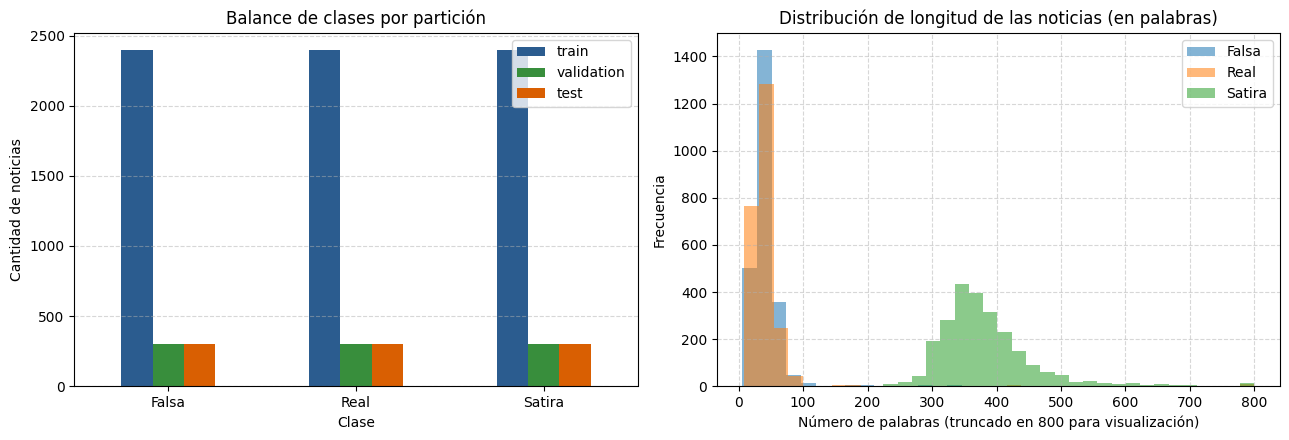

Estadísticas de longitud (en palabras) en Train:
         count        mean        std   min    50%     max
clase                                                     
Falsa   2400.0   46.007083  63.151521   6.0   38.0  2188.0
Real    2400.0   48.452083  84.024844   9.0   37.0  1342.0
Satira  2400.0  383.682500  85.917028  25.0  369.0  1338.0


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import concatenate_datasets, DatasetDict, ClassLabel

MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"
DATASET     = "gabrielhuav/Unified-and-Balanced-Spanish-Fake-News-Corpus"

# 1. Carga desde el Hub (indicando el separador ';' propio del CSV original)
raw_ds = load_dataset(DATASET, sep=";", on_bad_lines="skip")
print("Dataset original completo:", raw_ds)

# Mapeo de clases
id2label = {0: "Falsa", 1: "Real", 2: "Satira"}
label2id = {"Falsa": 0, "Real": 1, "Satira": 2}

# 2. Limpieza de nulos/duplicados exactos antes de partir (evita fugas de datos)
df_full = raw_ds["train"].to_pandas()
df_full = df_full.dropna(subset=["text", "label"]).copy()
df_full["text"] = df_full["text"].astype(str).str.strip()
df_full = df_full[df_full["text"].str.len() > 20]
df_full = df_full.drop_duplicates(subset=["text"]).reset_index(drop=True)

# 3. Submuestreo estratificado y balanceado (3.000 ejemplos por clase = 9.000 textos)
# Esto garantiza balance perfecto (33.3% por clase) y tiempos de entrenamiento óptimos en GPU T4
N_POR_CLASE = 3000
df_balanced = (
    df_full.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=N_POR_CLASE, random_state=CEDULA))
    .sample(frac=1.0, random_state=CEDULA)
    .reset_index(drop=True)
)

from datasets import Dataset
ds_base = Dataset.from_pandas(df_balanced[["text", "label"]], preserve_index=False)
ds_base = ds_base.cast_column("label", ClassLabel(names=["Falsa", "Real", "Satira"]))

# 4. Construcción de particiones con la semilla (80% train, 10% validation, 10% test)
split_train_temp = ds_base.train_test_split(test_size=0.20, seed=CEDULA, stratify_by_column="label")
split_val_test   = split_train_temp["test"].train_test_split(test_size=0.50, seed=CEDULA, stratify_by_column="label")

ds = DatasetDict({
    "train": split_train_temp["train"],
    "validation": split_val_test["train"],
    "test": split_val_test["test"]
})

print("\n--- TAMAÑO DE CADA PARTICIÓN ---")
for k in ds:
    print(f"{k:10s}: {len(ds[k])} ejemplos")

# 5. Verificación de fugas (Data Leakage) entre particiones
set_train = set(ds["train"]["text"])
set_val   = set(ds["validation"]["text"])
set_test  = set(ds["test"]["text"])
print("\n--- VERIFICACIÓN DE FUGAS ENTRE PARTICIONES ---")
print("Solapamiento Train ∩ Val :", len(set_train.intersection(set_val)))
print("Solapamiento Train ∩ Test:", len(set_train.intersection(set_test)))
print("Solapamiento Val   ∩ Test:", len(set_val.intersection(set_test)))

# 6. Ejemplos por clase
print("\n--- EJEMPLOS POR CLASE (Train) ---")
for label_id, nombre in id2label.items():
    ejemplo = next(x["text"] for x in ds["train"] if x["label"] == label_id)
    print(f"[{label_id} - {nombre}]: {ejemplo[:220]}...\n")

# 7. Gráficos: Balance de clases y Distribución de longitud de textos (en palabras)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico A: Balance de clases por partición
conteos = pd.DataFrame({
    split: pd.Series(ds[split]["label"]).map(id2label).value_counts()
    for split in ["train", "validation", "test"]
})
conteos.plot(kind="bar", ax=axes[0], rot=0, color=["#2b5c8f", "#388e3c", "#d95f02"])
axes[0].set_title("Balance de clases por partición")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Cantidad de noticias")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico B: Longitud en palabras por clase
longitudes = [len(t.split()) for t in ds["train"]["text"]]
clases_str = [id2label[l] for l in ds["train"]["label"]]
df_len = pd.DataFrame({"clase": clases_str, "palabras": longitudes})
for nombre, grupo in df_len.groupby("clase"):
    axes[1].hist(grupo["palabras"].clip(upper=800), bins=35, alpha=0.55, label=nombre)
axes[1].set_title("Distribución de longitud de las noticias (en palabras)")
axes[1].set_xlabel("Número de palabras (truncado en 800 para visualización)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Estadísticas de longitud (en palabras) en Train:")
print(df_len.groupby("clase")["palabras"].describe()[["count", "mean", "std", "min", "50%", "max"]])

## 3. Preprocesamiento

*El `processor`/`tokenizer` del modelo base y qué hace; construcción de la partición de validación con la semilla; aumento de datos si lo usan.*

## 4. Experimentos

Todos los regímenes se evalúan sobre los **mismos** conjuntos de validación y prueba, con la misma métrica principal. Registren cada uno con `registrar(...)` para que la tabla de la sección 5 salga sola.

In [ ]:
import pandas as pd
RESULTADOS = []

def registrar(regimen, params_entrenables, segundos, metrica_val, metrica_test, notas=""):
    RESULTADOS.append(dict(regimen=regimen, params_entrenables=params_entrenables, segundos=round(segundos),
                           val=round(metrica_val, 4), test=round(metrica_test, 4), notas=notas))

def tabla_resultados():
    return pd.DataFrame(RESULTADOS).set_index("regimen")

def params_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

### 4.1 Baseline sin preentrenamiento

*Un modelo pequeño desde cero sobre sus datos.*

### 4.2 Modelo base sin adaptar (si aplica)

*Zero-shot o cabeza compatible. Si no aplica, explíquenlo.*

### 4.3 Feature extraction

*Backbone congelado (`requires_grad = False` en `model.base_model`), solo la cabeza nueva.*

### 4.4 Fine-tuning completo

*Todo descongelado, tasa de aprendizaje baja; justifiquen tasa, épocas y criterio de parada con validación.*

### 4.5 Experimento adicional (cuenta para α)

*Eficiencia de datos, descongelado gradual, dos modelos base, catastrophic forgetting...*

## 5. Resultados y discusión

*Tabla, curvas, matriz de confusión del mejor modelo, errores típicos, y la discusión: qué ganó, por qué, cuánto costó, qué harían con más datos o cómputo.*

In [ ]:
tabla_resultados()

## 6. Modelo óptimo y publicación

*Criterio de optimalidad por escrito. Luego, publicar el modelo elegido y comprobar que se recarga tal como lo hará el API.*

In [ ]:
from huggingface_hub import login
login()                          # token con permiso de escritura (huggingface.co/settings/tokens)

REPO_ID = "usuario/mi-modelo"    # el mismo identificador que va en el .env del API
mejor_modelo.push_to_hub(REPO_ID)
processor.push_to_hub(REPO_ID)   # o tokenizer.push_to_hub(REPO_ID)

In [ ]:
# Prueba de recarga desde el Hub: exactamente lo que hace el API al arrancar
from transformers import pipeline
clf = pipeline("image-classification", model=REPO_ID, top_k=None)   # o "text-classification"
clf(ds["test"][0]["image"])                                         # o clf("un texto de prueba")

## 7. Conclusiones y limitaciones

*Qué aprendieron, dónde falla el modelo, sesgos de los datos, uso previsto. Este texto es también la base de la model card.*